12 Aug 2025: added chromatic correction\
Image registration done using starfish method\
3rd Sep double check consistency with lm39_aml_starfish_run10_multifov.ipynb and save starfish output as CSV

In [2]:
from IPython import get_ipython
import matplotlib
import matplotlib.pyplot as plt

import os
# ---- Main folder = the repository folder, which holds Data/ (layout described in Data/README.md). ----
# Run this from the folder the file is in, or set the environment variable GUIDESTAR_MAIN_DIR to the repository path.
main_dir = os.environ.get('GUIDESTAR_MAIN_DIR', '../..')


matplotlib.rcParams["figure.dpi"] = 150

In [1]:
## Load data
import pprint
import starfish

### must load from local storage!
exp_json_path = os.path.join(main_dir, "Data/benchmarking/starfish/liver/GS_lm39_tissue_single_channel_starfish/primary/experiment.json") # source: <main_dir>\Polaris_attempt\LM39_tissue\one_channel
experiment = starfish.Experiment.from_json(exp_json_path)

experiment

<starfish.Experiment (FOVs=49)>
{
fov_000: <starfish.FieldOfView>
  Primary Image: <slicedimage.TileSet (r: 16, z: 1, c: 1, x: 2048, y: 2048)>
  Auxiliary Images:
    
fov_001: <starfish.FieldOfView>
  Primary Image: <slicedimage.TileSet (r: 16, z: 1, c: 1, x: 2048, y: 2048)>
  Auxiliary Images:
    
fov_002: <starfish.FieldOfView>
  Primary Image: <slicedimage.TileSet (r: 16, z: 1, c: 1, x: 2048, y: 2048)>
  Auxiliary Images:
    
fov_003: <starfish.FieldOfView>
  Primary Image: <slicedimage.TileSet (r: 16, z: 1, c: 1, x: 2048, y: 2048)>
  Auxiliary Images:
    
  ...,
}

In [3]:
from starfish import FieldOfView
from starfish.types import Axes
from collections import defaultdict

pp = pprint.PrettyPrinter(indent=2)
pp.pprint(experiment._src_doc)
imgs = defaultdict()
for fov_data in experiment.fovs():
    print(fov_data.name)
    imgs[fov_data.name] = fov_data.get_image(FieldOfView.PRIMARY_IMAGES)
    
#imgs = experiment.fov().get_image(FieldOfView.PRIMARY_IMAGES)

{ 'codebook': 'codebook.json',
  'extras': {},
  'images': {'primary': 'primary.json'},
  'version': '5.0.0'}
fov_000
fov_001
fov_002
fov_003
fov_004
fov_005
fov_006
fov_007
fov_008
fov_009
fov_010
fov_011
fov_012
fov_013
fov_014
fov_015
fov_016
fov_017
fov_018
fov_019
fov_020
fov_021
fov_022
fov_023
fov_024
fov_025
fov_026
fov_027
fov_028
fov_029
fov_030
fov_031
fov_032
fov_033
fov_034
fov_035
fov_036
fov_037
fov_038
fov_039
fov_040
fov_041
fov_042
fov_043
fov_044
fov_045
fov_046
fov_047
fov_048


In [4]:
imgs['fov_000'].sel({Axes.ROUND: 0, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.data

100%|██████████| 16/16 [00:00<00:00, 50.97it/s]


array([[[[[0.00425727, 0.00450141, 0.00466926, ..., 0.00457771,
           0.00408942, 0.0043183 ],
          [0.00410468, 0.00442512, 0.00454719, ..., 0.00445563,
           0.00453193, 0.0043183 ],
          [0.00445563, 0.00422675, 0.0043183 , ..., 0.00428778,
           0.00442512, 0.00424201],
          ...,
          [0.00236515, 0.00250248, 0.002533  , ..., 0.00378424,
           0.00355535, 0.0034638 ],
          [0.00247196, 0.00282292, 0.00248722, ..., 0.00363165,
           0.00370794, 0.00352483],
          [0.00265507, 0.00259403, 0.00263981, ..., 0.00349432,
           0.00337224, 0.00354009]]]]], dtype=float32)

### Register, filter and scale raw data before decoding into spatially resolved gene expression

In [5]:
from skimage.transform import AffineTransform
import csv
import os
import re
def parseDaybook(filepath: str,
                 verbose: bool = True,
                 ) -> AffineTransform:
    """
    parse daybook lateral chromatic shift output file
    and generate affine matrix

    returns affine matrix ready for warping with skimage
    """
    title_row = None
    values_row = None

    with open(filepath) as csv_file:

        csv_reader = csv.reader(csv_file, delimiter=';')

        for row in csv_reader:
            if "a_affine_parameter" in row:
                title_row = [title.strip() for title in row]
            # go to next row. then stop reading
            elif title_row is not None:
                values_row = [float(value) for value in row]
                break

    assert title_row is not None, "title row for param values not found in daybook csv file"
    assert values_row is not None, "row containing param values not found in daybook csv file"

    matrix = np.zeros((3, 3), dtype=np.float64)
    matrix[0, 0] = values_row[title_row.index("a_affine_parameter")]
    matrix[0, 1] = values_row[title_row.index("b_affine_parameter")]
    matrix[1, 0] = values_row[title_row.index("c_affine_parameter")]
    matrix[1, 1] = values_row[title_row.index("d_affine_parameter")]
    matrix[0, 2] = values_row[title_row.index("x_translation_affine_parameter")]
    matrix[1, 2] = values_row[title_row.index("y_translation_affine_parameter")]
    matrix[2, 2] = 1

    if verbose:
        print("____ Matrix: ____\n", matrix)

    return AffineTransform(matrix)

In [6]:
from starfish.image import Filter
from starfish.types import Levels
from skimage.transform import warp as skimage_warp
import numpy as np
from copy import deepcopy

type_to_colour = {
    "Cy3": "558",
    "Cy5": "684",
    "Cy7": "776"
}
reference_colour = "684"
calibration_path = os.path.join(main_dir, 'Data/60uM/calibrationDory')
color_list = ['Cy7']*8 +['Cy5']*8
dropped_bits = []
ref_bit = 10

params_pattern1 = re.compile("[a-zA-Z]+(\d+)_[a-zA-Z]+(\d+)")
params_pattern2 = re.compile("([a-zA-Z0-9]+)to([a-zA-Z0-9]+)")

pairs_tf_dict = {}

for file in os.listdir(calibration_path):

    if os.path.splitext(file)[-1] == ".csv":

        match1 = re.search(params_pattern1, file)
        match2 = re.search(params_pattern2, file)

        if match1:
            match = match1
        elif match2:
            match = match2
        else:
            continue

        daybook_fullpath = os.path.join(calibration_path, file)
        colour_pair = (match.group(1), match.group(2))

        pairs_tf_dict[colour_pair] = parseDaybook(daybook_fullpath)
colours_tf_dict = {reference_colour: None}
for pair in pairs_tf_dict:
    if pair[0] == reference_colour:
        colours_tf_dict[pair[1]] = pairs_tf_dict[pair]
    if pair[1] == reference_colour:
        colours_tf_dict[pair[0]] = pairs_tf_dict[pair].inverse


ghp = Filter.GaussianHighPass(sigma=3)
dpsf = Filter.DeconvolvePSF(num_iter=15, sigma=2, level_method=Levels.SCALE_SATURATED_BY_CHUNK)
glp = Filter.GaussianLowPass(sigma=1)

aligned_imgs = deepcopy(imgs)

low_passed = defaultdict()
for fov_key in imgs.keys():
    print(fov_key)
    
    img = imgs[fov_key]

    print("Chromatic correction...")
    
    for bit, selector in enumerate(img._iter_axes()):
        colour = color_list[bit]
        print(
            f"Correcting chromatic distortion for bit {bit} with colour {colour}...\n"
        )

        if bit not in dropped_bits:
            transform = colours_tf_dict[type_to_colour[colour]]
            if transform is not None:
                slice_to_warp = aligned_imgs[fov_key].sel({Axes.ROUND: bit, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.squeeze().copy()
                align_slice = skimage_warp(slice_to_warp, transform)
                align_slice = np.expand_dims(align_slice, axis=0)
                aligned_imgs[fov_key].set_slice(selector, align_slice, [Axes.ZPLANE])
    
    print("Registering...")
    
    ref_img = aligned_imgs[fov_key].sel({Axes.ROUND: ref_bit, Axes.CH: 0, Axes.ZPLANE: 0})
    # print(f"Reference image: {ref_img}")
    
    # Register the image to the reference image using translation
    ltt = starfish.image.LearnTransform.Translation(
        reference_stack=ref_img,
        axes=Axes.ROUND,
        upsampling=1000,
    )
    transforms = ltt.run(aligned_imgs[fov_key])
    
    # print(f"transforms: {transforms}")

    warp = starfish.image.ApplyTransform.Warp()
    aligned_img = warp.run(
        stack=aligned_imgs[fov_key],
        transforms_list=transforms,
    )
    
    print("Filtering...")
    
    high_passed = ghp.run(aligned_img, verbose=True, in_place=False)
    
    # deconvolved = dpsf.run(high_passed, verbose=True, in_place=False)
    deconvolved = high_passed
    low_passed[fov_key] = glp.run(deconvolved, verbose=True, in_place=False,)

<>:18: SyntaxWarning: invalid escape sequence '\d'
<>:18: SyntaxWarning: invalid escape sequence '\d'
<user_home>\AppData\Local\Temp\ipykernel_49736\2967985996.py:18: SyntaxWarning: invalid escape sequence '\d'
  params_pattern1 = re.compile("[a-zA-Z]+(\d+)_[a-zA-Z]+(\d+)")


____ Matrix: ____
 [[ 1.00130105e+00  4.67026129e-06 -1.43742820e+00]
 [-4.67026129e-06  1.00130105e+00 -1.22251447e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
____ Matrix: ____
 [[ 1.00177926e+00  2.50579395e-05 -1.69703024e+00]
 [-2.50579395e-05  1.00177926e+00 -1.93060367e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
____ Matrix: ____
 [[ 9.97184823e-01 -2.92860502e-05  2.96042144e+00]
 [ 2.92860502e-05  9.97184823e-01  2.68954620e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
fov_000
Chromatic correction...
Correcting chromatic distortion for bit 0 with colour Cy7...

Correcting chromatic distortion for bit 1 with colour Cy7...

Correcting chromatic distortion for bit 2 with colour Cy7...

Correcting chromatic distortion for bit 3 with colour Cy7...

Correcting chromatic distortion for bit 4 with colour Cy7...

Correcting chromatic distortion for bit 5 with colour Cy7...

Correcting chromatic distortion for bit 6 with colour Cy7...

Correcting chro

100%|██████████| 16/16 [00:00<00:00, 442.71it/s]


fov_001
Chromatic correction...
Correcting chromatic distortion for bit 0 with colour Cy7...



100%|██████████| 16/16 [00:00<00:00, 69.01it/s]


Correcting chromatic distortion for bit 1 with colour Cy7...

Correcting chromatic distortion for bit 2 with colour Cy7...

Correcting chromatic distortion for bit 3 with colour Cy7...

Correcting chromatic distortion for bit 4 with colour Cy7...

Correcting chromatic distortion for bit 5 with colour Cy7...

Correcting chromatic distortion for bit 6 with colour Cy7...

Correcting chromatic distortion for bit 7 with colour Cy7...

Correcting chromatic distortion for bit 8 with colour Cy5...

Correcting chromatic distortion for bit 9 with colour Cy5...

Correcting chromatic distortion for bit 10 with colour Cy5...

Correcting chromatic distortion for bit 11 with colour Cy5...

Correcting chromatic distortion for bit 12 with colour Cy5...

Correcting chromatic distortion for bit 13 with colour Cy5...

Correcting chromatic distortion for bit 14 with colour Cy5...

Correcting chromatic distortion for bit 15 with colour Cy5...

Registering...
Filtering...


... (185 outputs left out)

fov_048
Chromatic correction...
Correcting chromatic distortion for bit 0 with colour Cy7...



100%|██████████| 16/16 [00:00<00:00, 54.94it/s]


Correcting chromatic distortion for bit 1 with colour Cy7...

Correcting chromatic distortion for bit 2 with colour Cy7...

Correcting chromatic distortion for bit 3 with colour Cy7...

Correcting chromatic distortion for bit 4 with colour Cy7...

Correcting chromatic distortion for bit 5 with colour Cy7...

Correcting chromatic distortion for bit 6 with colour Cy7...

Correcting chromatic distortion for bit 7 with colour Cy7...

Correcting chromatic distortion for bit 8 with colour Cy5...

Correcting chromatic distortion for bit 9 with colour Cy5...

Correcting chromatic distortion for bit 10 with colour Cy5...

Correcting chromatic distortion for bit 11 with colour Cy5...

Correcting chromatic distortion for bit 12 with colour Cy5...

Correcting chromatic distortion for bit 13 with colour Cy5...

Correcting chromatic distortion for bit 14 with colour Cy5...

Correcting chromatic distortion for bit 15 with colour Cy5...

Registering...
Filtering...


100%|██████████| 16/16 [00:00<00:00, 733.12it/s]


In [7]:
aligned_imgs['fov_000'].sel({Axes.ROUND: 0, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.data

array([[[[[0.00463339, 0.0047272 , 0.0046213 , ..., 0.00450161,
           0.00451392, 0.00447141],
          [0.0044731 , 0.0044901 , 0.00452656, ..., 0.00454684,
           0.00465167, 0.0043778 ],
          [0.00462383, 0.0045886 , 0.00435659, ..., 0.00437022,
           0.00447309, 0.0043249 ],
          ...,
          [0.00265896, 0.00256454, 0.00272548, ..., 0.00372002,
           0.00343462, 0.00343121],
          [0.00256972, 0.00250061, 0.00273261, ..., 0.00374032,
           0.00354585, 0.00341763],
          [0.00262561, 0.00247543, 0.00260347, ..., 0.00348904,
           0.00361759, 0.00362882]]]]], dtype=float32)

In [8]:
from starfish.types import Axes, Features
import numpy as np
from copy import deepcopy

filtered_imgs = deepcopy(low_passed)

In [9]:
# Compute global scale factor for each image based on the 99.9th percentile of pixel intensities
globalnorm_fovsubset = ['fov_010', 'fov_011', 'fov_012', 'fov_013', 'fov_014'] #lm39 cells
per_image_percentile_cut = 99.9
pooled_percentile = 57
scale_list = []

for bit in range(len(color_list)):
    print(f"Processing bit {bit}...")
    selector = {Axes.ROUND: bit, Axes.CH: 0, Axes.ZPLANE: 0}
    intensity_pooled = [] # pool intensity holder for each bit
    for fov_key in filtered_imgs.keys():
        if fov_key in globalnorm_fovsubset:
            print(f"Processing FOV {fov_key}...")
            raw_array = filtered_imgs[fov_key].sel(selector).xarray.data # select the image for that bit and fov
            # following GS per_image_sample_method == "highest"
            cutoff = np.percentile(raw_array, per_image_percentile_cut)
            subsampled_array = raw_array[raw_array > cutoff]
            intensity_pooled.append(subsampled_array.flat)
    intensity_pooled = np.concatenate(intensity_pooled, axis=None)
    # following method == "median":
    bit_normalization_value = np.percentile(intensity_pooled, pooled_percentile) # get the 57th median of the all the 99.9th percentile intensities in the selected fovs       
    scale_list.append(bit_normalization_value)      

Processing bit 0...
Processing FOV fov_010...
Processing FOV fov_011...
Processing FOV fov_012...
Processing FOV fov_013...
Processing FOV fov_014...
Processing bit 1...
Processing FOV fov_010...
Processing FOV fov_011...
Processing FOV fov_012...
Processing FOV fov_013...
Processing FOV fov_014...
Processing bit 2...
Processing FOV fov_010...
Processing FOV fov_011...
Processing FOV fov_012...
Processing FOV fov_013...
Processing FOV fov_014...
Processing bit 3...
Processing FOV fov_010...
Processing FOV fov_011...
Processing FOV fov_012...
Processing FOV fov_013...
Processing FOV fov_014...
Processing bit 4...
Processing FOV fov_010...
Processing FOV fov_011...
Processing FOV fov_012...
Processing FOV fov_013...
Processing FOV fov_014...
Processing bit 5...
Processing FOV fov_010...
Processing FOV fov_011...
Processing FOV fov_012...
Processing FOV fov_013...
Processing FOV fov_014...
Processing bit 6...
Processing FOV fov_010...
Processing FOV fov_011...
Processing FOV fov_012...
Pr

In [10]:
scale_factors = {}

for selector in filtered_imgs['fov_000']._iter_axes({Axes.ROUND, Axes.CH}):
    r = selector[Axes.ROUND]
    c = selector[Axes.CH]
    scale_factors[(r, c)] = scale_list[r]
scale_factors

{(0, 0): 0.0023614883003756403,
 (1, 0): 0.0019003357482142746,
 (2, 0): 0.0017859099130146205,
 (3, 0): 0.003801710964180529,
 (4, 0): 0.0030439630895853042,
 (5, 0): 0.001537589058279991,
 (6, 0): 0.0032949065836146473,
 (7, 0): 0.003913662023842334,
 (8, 0): 0.018390334323048593,
 (9, 0): 0.011007895488291978,
 (10, 0): 0.0100594000518322,
 (11, 0): 0.03469867415726185,
 (12, 0): 0.019609344899654386,
 (13, 0): 0.01151092905551195,
 (14, 0): 0.007106051873415708,
 (15, 0): 0.004799194522202015}

In [11]:
for fov_key in low_passed.keys():
    
    print(f"scaling {fov_key}...")

    tmp_img = filtered_imgs[fov_key]

    for selector in tmp_img._iter_axes():
        # print(selector)
        data = tmp_img.get_slice(selector)[0]
        print(f"{fov_key} | shape: {data.shape}, dtype: {data.dtype}, min: {np.min(data)}, max: {np.max(data):0.2f}")
        scaled = data  / scale_factors[selector[Axes.ROUND.value], selector[Axes.CH.value]]
        scaled = np.clip(scaled, 0, 1)

        # print(scaled.shape, scaled.dtype, np.min(scaled), np.max(scaled))
        tmp_img.set_slice(selector, scaled, [Axes.ZPLANE])

scaling fov_000...
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.01
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.01
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.01
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.05
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.01
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.01
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.01
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.01
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.04
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.05
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.10
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.39
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.05
fov_000 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.02
f

# Save the mip of the scaled image

In [12]:
mip_save_path = os.path.join(main_dir, 'Data/benchmarking/starfish/liver/starfish_result/')
if not os.path.exists(mip_save_path):
    os.makedirs(mip_save_path)
for fov_key in filtered_imgs.keys():
    print(f"projecting {fov_key}...")
    projected_imgs = filtered_imgs[fov_key].reduce({Axes.CH}, func="max")
    np.save(mip_save_path + fov_key + '_projected.npy', projected_imgs.xarray.data)

projecting fov_000...


100%|██████████| 16/16 [00:00<00:00, 126.96it/s]


projecting fov_001...


100%|██████████| 16/16 [00:00<00:00, 121.81it/s]


projecting fov_002...


100%|██████████| 16/16 [00:00<00:00, 126.00it/s]


... (88 outputs left out)

projecting fov_047...


100%|██████████| 16/16 [00:00<00:00, 118.23it/s]


projecting fov_048...


100%|██████████| 16/16 [00:00<00:00, 116.77it/s]


In [13]:
from starfish.spots import DetectPixels

psd = DetectPixels.PixelSpotDecoder(
    codebook=experiment.codebook,
    metric='euclidean', # distance metric to use for computing distance between a pixel vector and a codeword
    norm_order=2, # the L_n norm is taken of each pixel vector and codeword before computing the distance. this is n
    distance_threshold=0.5176, # minimum distance between a pixel vector and a codeword for it to be called as a gene
    magnitude_threshold=.2, # discard any pixel vectors below this magnitude
    min_area=2, # do not call a 'spot' if it's area is below this threshold (measured in pixels)
    max_area=np.inf, # do not call a 'spot' if it's area is above this threshold (measured in pixels)
)

spot_intensities_all = defaultdict()

for fov_key in filtered_imgs.keys():
    
    print(f"Decoding {fov_key}...")
    
    initial_spot_intensities, prop_results = psd.run(filtered_imgs[fov_key])
    # display(initial_spot_intensities)
    spot_intensities = initial_spot_intensities.loc[initial_spot_intensities[Features.PASSES_THRESHOLDS]]
    # display(spot_intensities)
    spot_intensities_all[fov_key] = spot_intensities

Decoding fov_000...


100%|██████████| 25873/25873 [00:00<00:00, 29270.42it/s]


Decoding fov_001...


100%|██████████| 33731/33731 [00:01<00:00, 33211.68it/s]


Decoding fov_002...


100%|██████████| 26851/26851 [00:00<00:00, 28815.11it/s]


... (88 outputs left out)

Decoding fov_047...


100%|██████████| 42591/42591 [00:01<00:00, 24321.59it/s]


Decoding fov_048...


100%|██████████| 44988/44988 [00:01<00:00, 34611.91it/s]


In [14]:
import pandas as pd

results_all = pd.Series(dtype=int)
df_features = pd.DataFrame()

for fov, spots in spot_intensities_all.items():
    tmp_features = spots.to_features_dataframe()
    tmp_features['fov'] = fov
    tmp_features['mean_intensity'] = spots.mean(axis=1).data
    df_features = pd.concat([df_features, tmp_features], ignore_index=True)
    genes, counts = np.unique(spots[Features.AXIS][Features.TARGET], return_counts=True)
    result_counts = pd.Series(counts, index=genes)
    total_counts = result_counts.sum()
    print(f"FOV: {fov}, Total spots: {total_counts}")
    # display(result_counts)
    results_all = results_all.add(result_counts, fill_value=0).astype(int)

results_all.name = "total_counts_per_gene"

# display(results_all)
print(f"total number of genes found: {results_all.sum()}")

FOV: fov_000, Total spots: 15024
FOV: fov_001, Total spots: 19555
FOV: fov_002, Total spots: 15504
FOV: fov_003, Total spots: 15254
FOV: fov_004, Total spots: 16840
FOV: fov_005, Total spots: 17068
FOV: fov_006, Total spots: 14351
FOV: fov_007, Total spots: 17815
FOV: fov_008, Total spots: 15835
FOV: fov_009, Total spots: 16589
FOV: fov_010, Total spots: 17448
FOV: fov_011, Total spots: 21260
FOV: fov_012, Total spots: 24706
FOV: fov_013, Total spots: 22329
FOV: fov_014, Total spots: 21521
FOV: fov_015, Total spots: 22297
FOV: fov_016, Total spots: 24113
FOV: fov_017, Total spots: 17869
FOV: fov_018, Total spots: 20929
FOV: fov_019, Total spots: 21877
FOV: fov_020, Total spots: 22363
FOV: fov_021, Total spots: 23677
FOV: fov_022, Total spots: 23018
FOV: fov_023, Total spots: 22103
FOV: fov_024, Total spots: 25317
FOV: fov_025, Total spots: 21277
FOV: fov_026, Total spots: 21671
FOV: fov_027, Total spots: 22433
FOV: fov_028, Total spots: 17403
FOV: fov_029, Total spots: 15872
FOV: fov_0

In [15]:
df_features.to_csv(mip_save_path+ "lm39_tissue_starfish_multifov.csv", index=False)

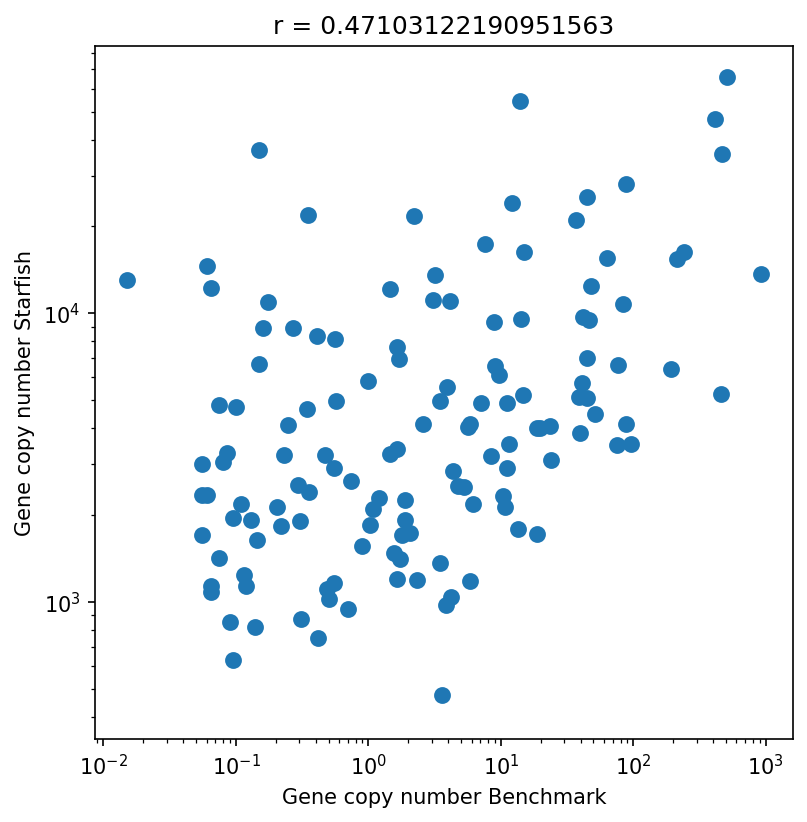

In [16]:
fpkm_path = os.path.join(main_dir, 'Data/60uM/codebook/fpkm_data.tsv')
bulk_fpkm = pd.read_csv(fpkm_path, sep='\t', index_col=0, header=None)

# display(bulk_fpkm)

comparison_df = pd.concat([results_all, bulk_fpkm], join='inner', axis=1)

# display(comparison_df)

tmp=comparison_df.values

r = np.corrcoef(tmp[:, 1], tmp[:, 0])[0, 1]
x = np.linspace(50, 2000)
f, ax = plt.subplots(figsize=(6, 6))
ax.scatter(tmp[:, 1], tmp[:, 0], 50, zorder=2)
# ax.plot(x, x, '-k', zorder=1)

plt.xlabel('Gene copy number Benchmark')
plt.ylabel('Gene copy number Starfish')
plt.xscale('log')
plt.yscale('log')
plt.title(f'r = {r}');


In [17]:
check = deconvolved.sel({Axes.ROUND: 0, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.data
print(check.min(), check.max(), check.mean(), check.shape)

0.0 0.028283568 8.9087865e-05 (1, 1, 1, 2048, 2048)


In [19]:
check = aligned_imgs['fov_012'].sel({Axes.ROUND: 0, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.data
print(check.min(), check.max(), check.mean(), check.shape)

0.0021745504 0.043816205 0.005769353 (1, 1, 1, 2048, 2048)


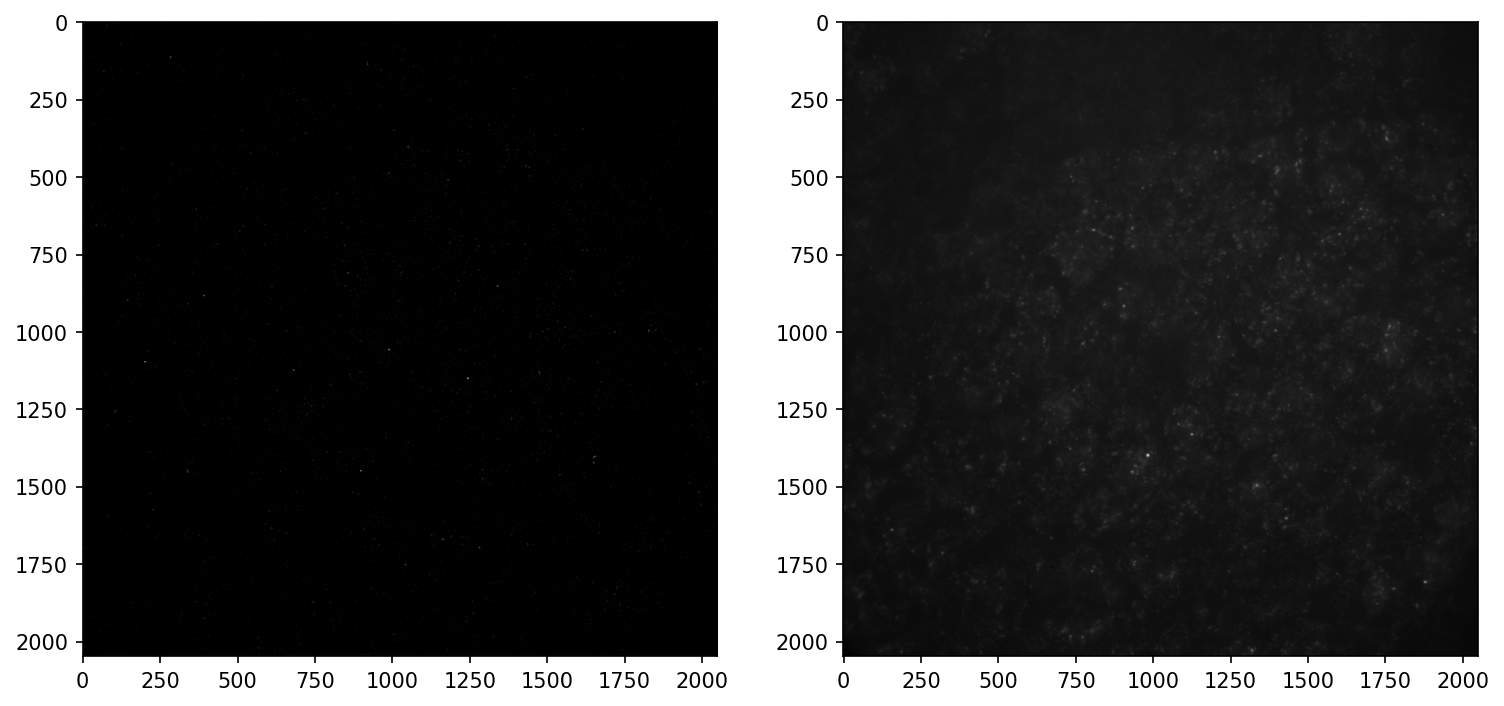

In [21]:
# plot deconvolved vs aligned for the same fov and bit
f, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(deconvolved.sel({Axes.ROUND: 0, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.data.reshape(2048,2048), cmap='gray')
ax[1].imshow(check.reshape(2048,2048), cmap='gray')
plt.show()